# AnyCam — 05c · Step 7 round 3: final SVCT configuration

Rounds 1-2 showed the consistency loss hurts and the best model was still improving at 80 epochs. Final setup:
- no consistency loss (one virtual camera per batch, full 204 bands 30% of the time), calibration errors 50%
- more phone-like practice cameras (45% rgb-like, 35% multispectral, 20% random); the 7 real cameras stay held out
- 150 epochs (patience 50)

Runs (~2.5 h): **SVCT final** (wavelength layer) and the clean ablation **same without wavelength layer**.
Setup: **HyperLeaf2024 (trophy)**, **GPU T4 x2**, **Internet On**. GitHub: **ShahnawazQ007/one-model-many-camera**,
file `kaggle_runs/05c_step7_round3.ipynb`.

In [1]:
import os, subprocess, glob, json, pathlib
REPO = 'https://github.com/ShahnawazQ007/one-model-many-camera.git'
if not os.path.exists('/kaggle/working/anycam'):
    subprocess.run(['git', 'clone', '-q', '--depth', '1', REPO, '/kaggle/working/anycam'], check=True)
else:
    subprocess.run(['git', '-C', '/kaggle/working/anycam', 'pull', '-q'], check=True)
os.chdir('/kaggle/working/anycam')
!pip -q install timm tifffile imagecodecs
import torch; print('GPU:', torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NONE - turn on the GPU accelerator!')
hits = [os.path.dirname(f) for f in glob.glob('/kaggle/input/**/train.csv', recursive=True)
        if os.path.isdir(os.path.join(os.path.dirname(f), 'images'))]
assert hits, 'Add Input -> search hyperleaf -> the one with the trophy icon'
DATA = hits[0]; print('data:', DATA, '| images:', len(glob.glob(f'{DATA}/images/*.tiff')))

GPU: Tesla T4
data: /kaggle/input/competitions/HyperLeaf2024 | images: 2410


In [2]:
# 1) SVCT final (ours)
!python experiments/train_svct.py --data {DATA} --stem hyper --views 1 --p-full 0.3 --radio 0.5 --sampler mixed --family-weights 0.45,0.35,0.2 --select acc --epochs 150 --patience 50 --out runs/svct_final

device cuda | train 1410 val 180 test 820 leaves | stem hyper views 1 cons 0.0 radio 0.5 held-out all

model.safetensors: downloading bytes: ████▍                 | 9.37MB            
model.safetensors: downloading bytes: ██████████████████████| 44.0MB, 4.31MB/s  
model.safetensors: reconstructing file: 100%|██████| 46.8MB / 46.8MB, 4.59MB/s  
model resnet18 (hyper stem): 11.60M parameters
epoch  0 train 2.305 val 2.723 acc 0.137 mse 1.316 (47s)
epoch  1 train 2.079 val 2.442 acc 0.386 mse 1.083 (71s)
epoch  2 train 1.841 val 2.481 acc 0.301 mse 0.894 (96s)
epoch  3 train 1.652 val 2.137 acc 0.436 mse 0.751 (118s)
epoch  4 train 1.503 val 1.957 acc 0.551 mse 0.790 (142s)
epoch  5 train 1.417 val 2.173 acc 0.458 mse 0.827 (165s)
epoch  6 train 1.325 val 1.998 acc 0.465 mse 0.779 (188s)
epoch  7 train 1.225 val 1.730 acc 0.638 mse 0.761 (213s)
epoch  8 train 1.141 val 1.798 acc 0.623 mse 0.810 (238s)
epoch  9 train 1.101 val 1.904 acc 0.596 mse 0.859 (264s)
epoch 10 train 1.070 val 1.953

In [3]:
# 2) clean ablation: identical, but no wavelength layer (bands interpolated back to 204)
!python experiments/train_svct.py --data {DATA} --stem interp --views 1 --p-full 0.3 --radio 0.5 --sampler mixed --family-weights 0.45,0.35,0.2 --select acc --epochs 150 --patience 50 --out runs/svct_final_interp

device cuda | train 1410 val 180 test 820 leaves | stem interp views 1 cons 0.0 radio 0.5 held-out all
model resnet18 (interp stem): 11.81M parameters
epoch  0 train 2.356 val 3.010 acc 0.000 mse 1.496 (44s)
epoch  1 train 2.176 val 3.010 acc 0.055 mse 1.495 (86s)
epoch  2 train 1.969 val 2.605 acc 0.232 mse 1.117 (126s)
epoch  3 train 1.861 val 2.293 acc 0.258 mse 0.831 (167s)
epoch  4 train 1.757 val 2.423 acc 0.273 mse 1.012 (208s)
epoch  5 train 1.658 val 2.343 acc 0.369 mse 0.950 (249s)
epoch  6 train 1.568 val 2.367 acc 0.360 mse 0.960 (289s)
epoch  7 train 1.502 val 2.259 acc 0.359 mse 0.776 (330s)
epoch  8 train 1.438 val 2.704 acc 0.258 mse 0.986 (371s)
epoch  9 train 1.385 val 2.520 acc 0.312 mse 1.011 (411s)
epoch 10 train 1.383 val 2.119 acc 0.391 mse 0.781 (451s)
epoch 11 train 1.296 val 2.075 acc 0.393 mse 0.669 (491s)
epoch 12 train 1.238 val 2.402 acc 0.400 mse 0.880 (532s)
epoch 13 train 1.203 val 2.167 acc 0.398 mse 0.821 (573s)
epoch 14 train 1.185 val 2.157 acc 0.44

Mean over the 7 real camera profiles (cameras the SVCT models never saw):
                 method   condition  cultivar_acc  Fertilizer_R2  GrainWeight_R2  PhiPS2_R2
204-band model (Step 6)       drift         0.521         -0.369          -0.667     -0.579
204-band model (Step 6) drift+radio         0.505         -0.488          -0.752     -0.695
204-band model (Step 6)     nominal         0.522         -0.364          -0.685     -0.562
204-band model (Step 6) radiometric         0.504         -0.509          -0.790     -0.567
      SVCT final (ours)       drift         0.669          0.540           0.498      0.224
      SVCT final (ours) drift+radio         0.640          0.462           0.430      0.122
      SVCT final (ours)     nominal         0.670          0.582           0.528      0.254
      SVCT final (ours) radiometric         0.650          0.502           0.447      0.205
    no wavelength layer       drift         0.730          0.464           0.423      0.219
    no

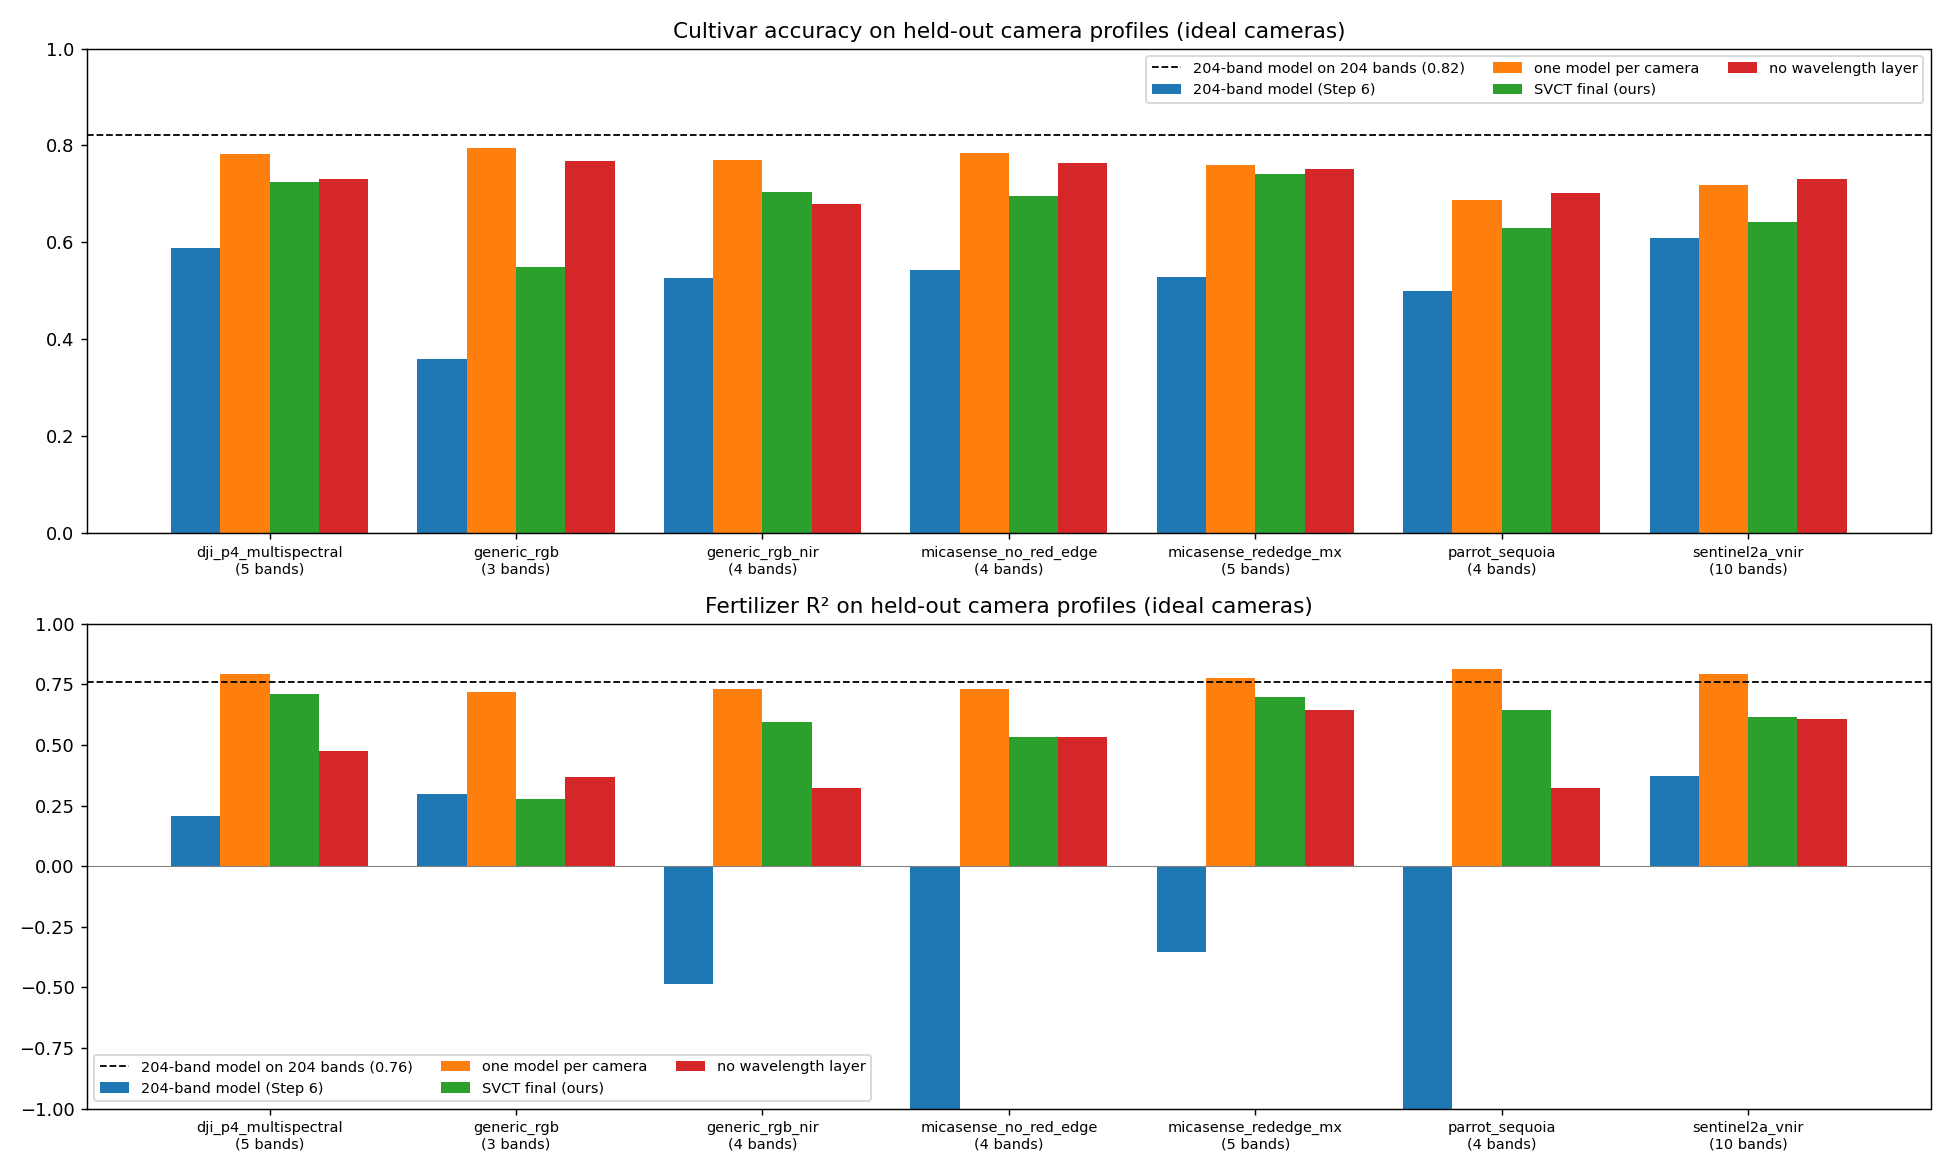

### results/step07_svct_round2/oracle_dji_p4_multispectral_metrics.json
{
 "split": "official",
 "seed": 0,
 "fold": 0,
 "backbone": "resnet18",
 "best_epoch": 21,
 "upscale": 2.0,
 "aug": "strong",
 "camera": "dji_p4_multispectral",
 "n_test": 820,
 "cultivar": {
  "accuracy": 0.7817073170731708,
  "macro_f1": 0.7741001073327313
 },
 "GrainWeight": {
  "R2": 0.7114541846291325,
  "RMSE": 1072.0557609562475
 },
 "Gsw": {
  "R2": 0.14327247189008097,
  "RMSE": 0.025184649023209577
 },
 "PhiPS2": {
  "R2": 0.47835009561907604,
  "RMSE": 0.07861934817444884
 },
 "Fertilizer": {
  "R2": 0.7909589271397718,
  "RMSE": 0.20759779847031795
 }
}
### results/step07_svct_round2/oracle_dji_p4_multispectral_metrics.json
{
 "split": "official",
 "seed": 0,
 "fold": 0,
 "backbone": "resnet18",
 "best_epoch": 21,
 "upscale": 2.0,
 "aug": "strong",
 "camera": "dji_p4_multispectral",
 "n_test": 820,
 "cultivar": {
  "accuracy": 0.7817073170731708,
  "macro_f1": 0.7741001073327313
 },
 "GrainWeight": {
 

In [6]:
import json, pathlib
for f in pathlib.Path('results/step07_svct_round2').glob('oracle_*_metrics.json'):
    d = pathlib.Path('runs/oracles') / f.name.replace('_metrics.json', '')
    d.mkdir(parents=True, exist_ok=True)
    (d / 'metrics.json').write_text(f.read_text())
!python scripts/plot_step7.py --baseline results/step06_camera_test/camera_eval.csv --oracles "runs/oracles/oracle_*" --runs "SVCT final (ours)=runs/svct_final" "no wavelength layer=runs/svct_final_interp" --out runs/step7_final
from IPython.display import Image, display
display(Image('runs/step7_final/step7_compare.png'))
!for f in runs/svct_final*/camera_eval.csv; do echo "### $f"; cat $f; done

## Done
**Save Version → Quick Save** → GitHub repository **ShahnawazQ007/one-model-many-camera**, file
`kaggle_runs/05c_step7_round3.ipynb`. Stop the session (power button). Tell Claude "done".